# BME 574 — Transfer learning
### Borrowing a trained backbone, and measuring what it is actually worth

Transfer learning is the first thing anyone reaches for on a small medical dataset: take a network
trained on something else, keep its features, retrain the head. This notebook does three things:

1. **Measures the benefit**, on a self-contained experiment you can rerun in two minutes — and
   shows that it depends almost entirely on **how much target data you have**.
2. Shows **the recipe in code**: feature extraction, fine-tuning, and the five details that cost
   people days.
3. Shows **the real thing** — a pretrained ResNet-18 from torchvision — written correctly.

**Runtime** about four minutes for §1–§3. §4 needs to download pretrained weights, so it needs a
network connection; it skips cleanly if there is none.

**Self-contained.** It imports nothing local and needs no file beside it.

In [14]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader

plt.rcParams.update({'font.size': 9, 'figure.dpi': 120})
NAVY, RED, GREEN, GREY = '#1F3864', '#9C2B2B', '#2E6B4F', '#9A9AA5'
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
SEED = 0
torch.manual_seed(SEED)

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((MNIST_MEAN,), (MNIST_STD,))])
train_dataset = torchvision.datasets.MNIST('./data', train=True, download=True,
                                           transform=transform)
test_dataset = torchvision.datasets.MNIST('./data', train=False, download=True,
                                          transform=transform)
to_t = lambda u8: (((u8.float() / 255.0) - MNIST_MEAN) / MNIST_STD).unsqueeze(1)
Xtr, ytr = to_t(train_dataset.data), train_dataset.targets.clone()
Xte, yte = to_t(test_dataset.data), test_dataset.targets.clone()
print('MNIST loaded:', tuple(Xtr.shape))

MNIST loaded: (60000, 1, 28, 28)


---
# 1 · A transfer experiment with no download

To ask "is transfer worth it?" honestly we need a **source task** and a **target task** that are
related but not the same, and we need to vary how much target data we have.

MNIST gives us both for free:

- **Source task**: classify digits **5–9**. About 29,000 images. We train a backbone on this.
- **Target task**: classify digits **0–4**. Related — the same strokes, the same acquisition — but
  not one label in common.

Then we train on the target task three ways, at four different target-set sizes:

| | |
|---|---|
| **from scratch** | random initialisation, train everything |
| **frozen features** | load the source backbone, freeze it, train only the new head |
| **fine-tuned** | load the source backbone, train everything at a lower learning rate |

This is the real question in miniature, and it runs on a laptop.

source task  : 29404 images (digits 5-9)
target pool  : 30596 images (digits 0-4)
target test  :  5139 images


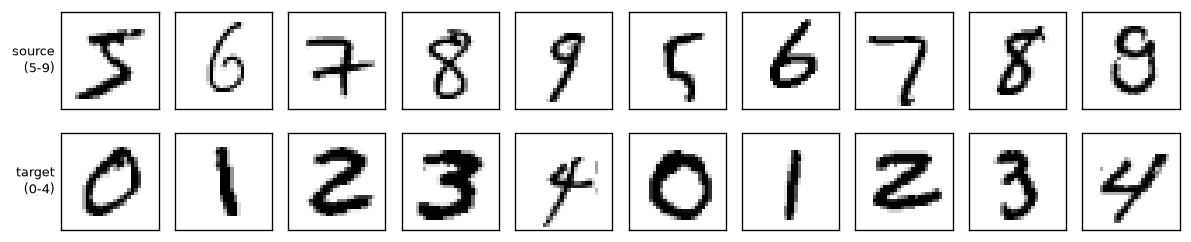

In [2]:
src = ytr >= 5
Xs, ys = Xtr[src], ytr[src] - 5                 # source: digits 5-9, relabelled 0-4
tgt = ytr < 5
Xt_all, yt_all = Xtr[tgt], ytr[tgt]             # target pool: digits 0-4
te_m = yte < 5
Xq, yq = Xte[te_m], yte[te_m]                   # target test set

print('source task  : %5d images (digits 5-9)' % len(ys))
print('target pool  : %5d images (digits 0-4)' % len(yt_all))
print('target test  : %5d images' % len(yq))

fig, ax = plt.subplots(2, 10, figsize=(10, 2.3))
for j in range(10):
    i_s = int(torch.where(ys == j % 5)[0][j])
    i_t = int(torch.where(yt_all == j % 5)[0][j])
    ax[0, j].imshow(train_dataset.data[src][i_s], cmap='gray_r')
    ax[1, j].imshow(train_dataset.data[tgt][i_t], cmap='gray_r')
    for r in range(2):
        ax[r, j].set_xticks([]); ax[r, j].set_yticks([])
ax[0, 0].set_ylabel('source\n(5-9)', fontsize=8, rotation=0, ha='right', va='center')
ax[1, 0].set_ylabel('target\n(0-4)', fontsize=8, rotation=0, ha='right', va='center')
plt.tight_layout(); plt.show()

In [3]:
def backbone():
    # everything except the classifier: image -> feature vector
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten())


def make_model(seed=SEED, n_out=5):
    torch.manual_seed(seed)
    return nn.Sequential(backbone(), nn.Linear(32 * 7 * 7, n_out))


def train(m, X, y, epochs, lr=1e-3, bs=64, seed=SEED):
    loader = DataLoader(TensorDataset(X, y), batch_size=min(bs, len(X)), shuffle=True,
                        generator=torch.Generator().manual_seed(seed + 5))
    # only hand the optimiser the parameters that are actually trainable
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=lr)
    lossfn = nn.CrossEntropyLoss()
    for _ in range(epochs):
        m.train()
        for xb, yb in loader:
            opt.zero_grad(); lossfn(m(xb), yb).backward(); opt.step()
    m.eval()
    return m


def accuracy(m, X, y, bs=2000):
    m.eval()
    with torch.no_grad():
        p = torch.cat([m(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])
    return float((p == y).double().mean())


print('--- pretraining the source model on digits 5-9')
t0 = time.time()
source_model = make_model(seed=SEED)
train(source_model, Xs, ys, epochs=3)
SOURCE_WEIGHTS = {k: v.clone() for k, v in source_model[0].state_dict().items()}
print('    done in %.0f s. The backbone has %s parameters; this is what we transfer.'
      % (time.time() - t0, format(sum(p.numel() for p in source_model[0].parameters()), ',')))

--- pretraining the source model on digits 5-9
    done in 19 s. The backbone has 4,800 parameters; this is what we transfer.


In [5]:
SIZES = [50, 200, 1000, 5000]
SEEDS = [0, 1, 2]
EPOCHS = {50: 40, 200: 25, 1000: 12, 5000: 8}   # so each condition sees similar step counts
RES = {c: {} for c in ('scratch', 'frozen', 'finetune')}
rng = np.random.default_rng(0)

print('%-7s %10s %10s %10s' % ('n', 'scratch', 'frozen', 'finetune'))
print('-' * 42)
for n in SIZES:
    for cond in RES:
        accs = []
        for sd in SEEDS:
            idx = torch.tensor(rng.choice(len(yt_all), n, replace=False))
            X, y = Xt_all[idx], yt_all[idx]
            m = make_model(seed=sd)
            if cond != 'scratch':
                m[0].load_state_dict(SOURCE_WEIGHTS)         # <- the transfer
            if cond == 'frozen':
                for p in m[0].parameters():
                    p.requires_grad = False                  # <- feature extraction
            lr = 1e-3 if cond != 'finetune' else 3e-4        # <- lower LR when fine-tuning
            train(m, X, y, epochs=EPOCHS[n], lr=lr, seed=sd)
            accs.append(accuracy(m, Xq, yq))
        RES[cond][n] = (float(np.mean(accs)), float(np.std(accs)))
    print('%-7d %10.4f %10.4f %10.4f'
          % (n, RES['scratch'][n][0], RES['frozen'][n][0], RES['finetune'][n][0]))

n          scratch     frozen   finetune
------------------------------------------
50          0.8756     0.9163     0.9285
200         0.9565     0.9755     0.9740
1000        0.9812     0.9877     0.9839
5000        0.9942     0.9944     0.9907


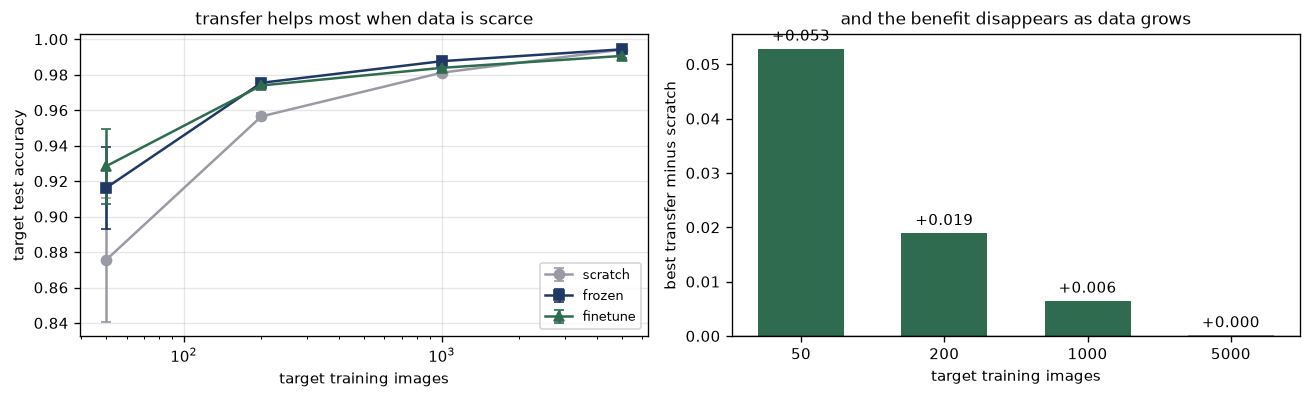

benefit of transfer, best condition minus scratch:
   n = 50    +0.0529
   n = 200   +0.0189
   n = 1000  +0.0065
   n = 5000  +0.0001


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for cond, col, mk in (('scratch', GREY, 'o'), ('frozen', NAVY, 's'),
                      ('finetune', GREEN, '^')):
    mu = [RES[cond][n][0] for n in SIZES]
    sd = [RES[cond][n][1] for n in SIZES]
    ax[0].errorbar(SIZES, mu, yerr=sd, marker=mk, color=col, label=cond, capsize=3)
ax[0].set_xscale('log'); ax[0].set_xlabel('target training images')
ax[0].set_ylabel('target test accuracy'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[0].set_title('transfer helps most when data is scarce', fontsize=10)

gain = [max(RES['frozen'][n][0], RES['finetune'][n][0]) - RES['scratch'][n][0] for n in SIZES]
ax[1].bar(range(len(SIZES)), gain, color=[GREEN if g > 0.005 else GREY for g in gain], width=.6)
for i, g in enumerate(gain):
    ax[1].text(i, g + 0.0015, '%+.3f' % g, ha='center', fontsize=9)
ax[1].axhline(0, color='black', lw=.8)
ax[1].set_xticks(range(len(SIZES))); ax[1].set_xticklabels([str(n) for n in SIZES])
ax[1].set_xlabel('target training images')
ax[1].set_ylabel('best transfer minus scratch')
ax[1].set_title('and the benefit disappears as data grows', fontsize=10)
plt.tight_layout(); plt.show()

print('benefit of transfer, best condition minus scratch:')
for n, g in zip(SIZES, gain):
    print('   n = %-5d %+.4f' % (n, g))

### Read the right thing off that

The benefit is large when you have fifty images and **gone** by the time you have a few thousand.
That is not a quirk of MNIST — it is the central finding of the paper this course cites on the
subject:

> Raghu, Zhang, Kleinberg & Bengio, **"Transfusion: Understanding Transfer Learning for Medical
> Imaging"**, NeurIPS 2019. On retinal fundus photographs and chest X-rays, ImageNet transfer gave
> *little* benefit to final performance; much smaller architectures did as well; and meaningful
> feature reuse was concentrated in the lowest layers.

They also found that the **convergence speedup** transfer appears to give is largely recovered by
initialising with only the *mean and variance* of the pretrained weights. In other words, a good
part of what looks like "borrowed features" is really just a sensible weight scale.

So: still the right first move when your dataset is small. Not an explanation of why a model works,
and not something to claim a large benefit from without measuring it on *your* data — which is
what this notebook just showed you how to do.

---
# 2 · The details that cost people days

Five things, all of which fail quietly.

In [7]:
# 1 -- grayscale into a 3-channel backbone.
#      Repeating the channel is the usual move; summing the first conv's weights
#      across input channels is the better one, because it preserves the filter's
#      response to a grey image instead of tripling it.
gray = Xtr[:2]
rgb_repeat = gray.repeat(1, 3, 1, 1)
print('repeat:', tuple(gray.shape), '->', tuple(rgb_repeat.shape))

conv_rgb = nn.Conv2d(3, 16, 3, padding=1)
conv_gray = nn.Conv2d(1, 16, 3, padding=1)
with torch.no_grad():
    conv_gray.weight.copy_(conv_rgb.weight.sum(dim=1, keepdim=True))   # <- sum, not mean
    conv_gray.bias.copy_(conv_rgb.bias)
    same = torch.allclose(conv_rgb(rgb_repeat), conv_gray(gray), atol=1e-5)
print('summing the input-channel weights reproduces the RGB result exactly:', same)

repeat: (2, 1, 28, 28) -> (2, 3, 28, 28)
summing the input-channel weights reproduces the RGB result exactly: True


In [9]:
# 2 -- normalisation. A pretrained backbone was fitted to ImageNet's statistics,
#      so use ImageNet's numbers, not your dataset's.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
imagenet_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
print('ImageNet normalisation:', IMAGENET_MEAN, IMAGENET_STD)
print('MNIST normalisation   : [%.4f] [%.4f]' % (MNIST_MEAN, MNIST_STD))
print()
print('3 -- resizing 28x28 up to 224x224 adds no information. It is legitimate,')
print('     it is what the backbone expects, and you should say plainly in a report')
print('     that you are paying 64x the compute for zero extra signal.')

ImageNet normalisation: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
MNIST normalisation   : [0.1307] [0.3081]

3 -- resizing 28x28 up to 224x224 adds no information. It is legitimate,
     it is what the backbone expects, and you should say plainly in a report
     that you are paying 64x the compute for zero extra signal.


In [10]:
# 4 -- freezing. requires_grad=False is only half of it: a frozen backbone with
#      BatchNorm still UPDATES its running statistics in train() mode.
bb = backbone()
for p in bb.parameters():
    p.requires_grad = False
demo = nn.Sequential(nn.Conv2d(1, 4, 3, padding=1), nn.BatchNorm2d(4))
for p in demo.parameters():
    p.requires_grad = False

demo.train()                                  # frozen weights, but TRAINING mode
before = demo[1].running_mean.clone()
with torch.no_grad():
    demo(Xtr[:64])
print('running_mean moved while "frozen", in train() mode :', not torch.allclose(before, demo[1].running_mean))

demo.eval()                                   # the fix
before = demo[1].running_mean.clone()
with torch.no_grad():
    demo(Xtr[:64])
print('running_mean moved while "frozen", in eval()  mode :', not torch.allclose(before, demo[1].running_mean))
print()
print('So a truly frozen backbone needs BOTH requires_grad=False AND .eval().')
print('Miss the second and your "frozen" features drift, on batches of whatever')
print('size you happened to choose.')

running_mean moved while "frozen", in train() mode : True
running_mean moved while "frozen", in eval()  mode : False

So a truly frozen backbone needs BOTH requires_grad=False AND .eval().
Miss the second and your "frozen" features drift, on batches of whatever
size you happened to choose.


In [11]:
# 5 -- the untrained head destroys the features in epoch 1. Its random weights
#      produce large gradients that flow straight back into the backbone.
#      Warm up: freeze, train the head, then unfreeze at a low learning rate.
def two_stage(X, y, Xv, yv, warmup=8, finetune=8, seed=SEED):
    m = make_model(seed=seed)
    m[0].load_state_dict(SOURCE_WEIGHTS)
    for p in m[0].parameters():
        p.requires_grad = False
    train(m, X, y, epochs=warmup, lr=1e-3, seed=seed)         # stage 1: head only
    for p in m[0].parameters():
        p.requires_grad = True
    train(m, X, y, epochs=finetune, lr=1e-4, seed=seed)       # stage 2: everything, low LR
    return accuracy(m, Xv, yv)


idx = torch.tensor(np.random.default_rng(1).choice(len(yt_all), 200, replace=False))
Xn, yn = Xt_all[idx], yt_all[idx]
a_naive = []
a_staged = []
for sd in [0, 1, 2]:
    m = make_model(seed=sd); m[0].load_state_dict(SOURCE_WEIGHTS)
    train(m, Xn, yn, epochs=16, lr=1e-3, seed=sd)
    a_naive.append(accuracy(m, Xq, yq))
    a_staged.append(two_stage(Xn, yn, Xq, yq, seed=sd))
print('n = 200, 3 seeds')
print('   fine-tune everything at once : %.4f' % np.mean(a_naive))
print('   warm up the head first       : %.4f' % np.mean(a_staged))
print('   difference                   : %+.4f' % (np.mean(a_staged) - np.mean(a_naive)))

n = 200, 3 seeds
   fine-tune everything at once : 0.9700
   warm up the head first       : 0.9722
   difference                   : +0.0021


---
# 3 · The real thing: a pretrained ResNet-18

Everything above used a backbone we trained ourselves, so that it runs anywhere. In practice you
would start from ImageNet weights, and the API is three lines.

**This section downloads about 45 MB of weights.** If there is no network it prints a message and
carries on — nothing below depends on it.

In [12]:
import torchvision.models as models

PRETRAINED = None
try:
    weights = models.ResNet18_Weights.DEFAULT          # the current best checkpoint
    PRETRAINED = models.resnet18(weights=weights)
    print('downloaded:', weights)
    print('   its preprocessing:', weights.transforms())
except Exception as e:
    print('could not download pretrained weights (%s: %s)' % (type(e).__name__, str(e)[:90]))
    print('   -> falling back to a randomly initialised ResNet-18 so the code below still runs.')
    print('      The STRUCTURE is identical; only the weights are not ImageNet ones.')
    PRETRAINED = models.resnet18(weights=None)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/hstrey/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%

downloaded: ResNet18_Weights.IMAGENET1K_V1
   its preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [13]:
model = PRETRAINED
total = sum(p.numel() for p in model.parameters())
print('ResNet-18: %s parameters, classifier head = %s'
      % (format(total, ','), model.fc))

# --- adapt it to a 5-class, single-channel problem -------------------------
# (a) new head
model.fc = nn.Linear(model.fc.in_features, 5)

# (b) a 1-channel stem, keeping the pretrained filters by summing across RGB
old = model.conv1
new = nn.Conv2d(1, old.out_channels, old.kernel_size, old.stride, old.padding, bias=False)
with torch.no_grad():
    new.weight.copy_(old.weight.sum(dim=1, keepdim=True))
model.conv1 = new

print('after adaptation: conv1 =', model.conv1)
print('                  fc    =', model.fc)
print()
# (c) freeze everything except the head
for name, p in model.named_parameters():
    p.requires_grad = name.startswith('fc.')
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('trainable: %s of %s parameters (%.2f%%)'
      % (format(trainable, ','), format(total, ','), 100 * trainable / total))
print()
# (d) and freeze the BatchNorm statistics too
model.eval()
with torch.no_grad():
    out = model(torch.nn.functional.interpolate(Xq[:4], size=64, mode='bilinear',
                                                align_corners=False))
print('forward pass on 4 upsampled MNIST images ->', tuple(out.shape))

ResNet-18: 11,689,512 parameters, classifier head = Linear(in_features=512, out_features=1000, bias=True)
after adaptation: conv1 = Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
                  fc    = Linear(in_features=512, out_features=5, bias=True)

trainable: 2,565 of 11,689,512 parameters (0.02%)

forward pass on 4 upsampled MNIST images -> (4, 5)


### What that cell did, in order

1. **Replaced the head.** `model.fc` was `Linear(512, 1000)` for ImageNet's thousand classes; it
   becomes `Linear(512, 5)`. The 512 is the backbone's output width — read it off rather than
   hard-coding it.
2. **Made the stem accept one channel**, summing the pretrained RGB filters so a grey image gives
   the same response it would have as a repeated 3-channel image.
3. **Froze everything but the head** — the cell prints what fraction that leaves trainable; it is a few thousand parameters out of 11.7 million.
4. **Called `.eval()`**, so the frozen BatchNorm layers stop updating their running statistics.

Fine-tuning instead of feature extraction is one change: set `requires_grad = True` on the layers
you want to move, and drop the learning rate by 10–100×.

---
## Summary

| | |
|---|---|
| **When transfer helps** | when target data is scarce. Measured here: **+0.05 at n = 50, nothing at n = 5000** |
| **Feature extraction** | freeze the backbone, train the head. The default on a few hundred images |
| **Fine-tuning** | unfreeze, 10–100× lower learning rate, after warming up the head |
| **Grayscale** | sum the first conv's input-channel weights; do not just repeat and hope |
| **Normalisation** | the backbone's statistics, not yours |
| **Freezing** | `requires_grad = False` **and** `.eval()`, or BatchNorm keeps moving |
| **The honest line** | "we used a pretrained ResNet" is not an explanation. Measure the benefit on your own data — that is the experiment in §1 |